# College Football Upset Vulnerability — Notebook 10: Historical Efficiency and Pregame Elo


## 0. Load Notebook 09 artifacts and previous project data


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/CFB_Upset_Project')
PROCESSED = PROJECT_DIR / 'data' / 'processed'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'validation'
INPUTS = {
    'team_games': PROCESSED / 'team_games.csv',
    'matchups': PROCESSED / 'matchup_features_offense_defense.csv',
    'feature_manifest': PROCESSED / 'offense_defense_feature_manifest.json',
    'eligibility': PROCESSED / 'game_eligibility_and_splits.csv',
    'split_manifest': PROCESSED / 'split_manifest.json',
    'notebook09_oof': OUTPUT_DIR / 'offense_defense_oof_predictions_2019_2023.csv',
}
missing=[f'{name}: {path}' for name,path in INPUTS.items() if not path.is_file()]
if missing: raise FileNotFoundError('Export Notebook 09 first. Missing:\n' + '\n'.join(missing))
team_games=pd.read_csv(INPUTS['team_games'],parse_dates=['date'],low_memory=False)
matchups=pd.read_csv(INPUTS['matchups'],parse_dates=['date'],low_memory=False)
eligibility=pd.read_csv(INPUTS['eligibility'],low_memory=False)
feature_manifest=json.loads(INPUTS['feature_manifest'].read_text(encoding='utf-8'))
split_manifest=json.loads(INPUTS['split_manifest'].read_text(encoding='utf-8'))
prior_oof=pd.read_csv(INPUTS['notebook09_oof'])
folds=split_manifest['validation_folds']
TEST_SEASONS=set(map(int,split_manifest['test_seasons']))
BASE88=list(feature_manifest['feature_sets']['efficiency_without_scoring'])
assert len(BASE88)==88 and len(BASE88)==len(set(BASE88))
assert set(BASE88).issubset(matchups.columns)
assert [int(f['validation_season']) for f in folds]==[2019,2020,2021,2022,2023]
assert TEST_SEASONS=={2024,2025}
assert len(matchups)==len(eligibility)==len(team_games)//2==18300
assert matchups.game_id.is_unique and eligibility.game_id.is_unique
assert team_games.groupby('game_id').size().eq(2).all()
print('Loaded:',len(matchups),'games /',len(team_games),'team-games')
print('Notebook 09 baseline:',len(BASE88),'features; folds:',[int(f['validation_season']) for f in folds])
print('Test seasons reserved:',sorted(TEST_SEASONS))
print('Python libraries: pandas',pd.__version__,'| scikit-learn',sklearn.__version__)

Mounted at /content/drive
Loaded: 18300 games / 36600 team-games
Notebook 09 baseline: 88 features; folds: [2019, 2020, 2021, 2022, 2023]
Test seasons reserved: [2024, 2025]
Python libraries: pandas 2.2.3 | scikit-learn 1.6.1


## 1. Verify team-game records and historical FBS membership



In [ ]:
ELIG_COLS=['game_id','season','home','away','home_subdivision','away_subdivision','primary_fbs_fbs']
assert set(ELIG_COLS).issubset(eligibility.columns)
tg=team_games.merge(eligibility[ELIG_COLS],on=['game_id','season'],how='left',validate='many_to_one',indicator=True)
assert tg['_merge'].eq('both').all()
tg=tg.drop(columns='_merge')
home_flag=tg.designated_home.astype('string').str.lower().str.strip()
assert home_flag.isin(['true','false','1','0']).all()
tg['designated_home']=home_flag.isin(['true','1'])
assert (tg.team.to_numpy()==np.where(tg.designated_home,tg.home,tg.away)).all()
assert (tg.opponent.to_numpy()==np.where(tg.designated_home,tg.away,tg.home)).all()
tg['opponent_subdivision']=np.where(tg.designated_home,tg.away_subdivision,tg.home_subdivision)
tg['opponent_is_fbs']=tg.opponent_subdivision.eq('fbs')
tg=tg.sort_values(['team','season','date','game_id'],kind='stable').reset_index(drop=True)
assert tg.date.notna().all() and not tg.duplicated(['team','date']).any()
assert tg.groupby('game_id').size().eq(2).all()
print('Opponent subdivision counts:')
display(tg.opponent_subdivision.value_counts(dropna=False).rename('team_games').to_frame())

Opponent subdivision counts:


,team_games
opponent_subdivision,
fbs,34469
fcs,2105
unknown,25
d2,1


## 2. Historical efficiency from the preceding three seasons only



In [ ]:
# Definitions match the rate conventions in Notebook 09.
SPECS={}
for role in ['for','against']:
    SPECS[f'pass_ypa_{role}']=(f'pass_yards_{role}',f'pass_att_{role}')
    SPECS[f'rush_ypc_{role}']=(f'rush_yards_{role}',f'rush_att_{role}')
    SPECS[f'completion_rate_{role}']=(f'pass_comp_{role}',f'pass_att_{role}')
    SPECS[f'third_down_rate_{role}']=(f'third_down_comp_{role}',f'third_down_att_{role}')
    tg[f'_attempts_{role}']=pd.to_numeric(tg[f'rush_att_{role}'],errors='coerce') + pd.to_numeric(tg[f'pass_att_{role}'],errors='coerce')
    SPECS[f'yards_per_play_{role}']=(f'total_yards_{role}',f'_attempts_{role}')
for pair in SPECS.values():
    for col in pair:
        assert col in tg.columns, f'Missing historical box-score field {col}'
        tg[col]=pd.to_numeric(tg[col],errors='coerce')

# Aggregate one completed team-season at a time, with valid observations separately for each statistic.
annual=tg[['team','season']].drop_duplicates().sort_values(['team','season']).reset_index(drop=True)
annual['fbs_games']=tg.loc[tg.opponent_is_fbs].groupby(['team','season']).size().reindex(
    pd.MultiIndex.from_frame(annual[['team','season']]),fill_value=0).to_numpy()
for metric,(num_col,den_col) in SPECS.items():
    valid=tg.opponent_is_fbs & tg[num_col].notna() & tg[den_col].notna() & tg[den_col].gt(0)
    part=tg.loc[valid,['team','season',num_col,den_col]].groupby(['team','season']).sum()
    idx=pd.MultiIndex.from_frame(annual[['team','season']])
    annual[f'{metric}__num']=part[num_col].reindex(idx,fill_value=0).to_numpy()
    annual[f'{metric}__den']=part[den_col].reindex(idx,fill_value=0).to_numpy()

# Cross-year lookup; season 2021 uses only 2020/2019/2018.
keys=annual[['team','season']].copy()
METRICS=list(SPECS)
for lag in [1,2,3]:
    prior=annual.rename(columns={'season':'prior_season',**{
        c:f'lag{lag}__{c}' for c in annual.columns if c not in ['team','season']}})
    keys[f'_lag{lag}_season']=keys.season-lag
    keys=keys.merge(prior,left_on=['team',f'_lag{lag}_season'],right_on=['team','prior_season'],
                    how='left',validate='many_to_one').drop(columns='prior_season')
    keys[f'lag{lag}__fbs_games']=keys[f'lag{lag}__fbs_games'].fillna(0)
    for metric in METRICS:
        for suffix in ['num','den']:
            c=f'lag{lag}__{metric}__{suffix}'
            keys[c]=keys[c].fillna(0)

keys['hist3_fbs_games']=sum(keys[f'lag{lag}__fbs_games'] for lag in [1,2,3])
HIST_SIDE=[]
for metric in METRICS:
    numerator=sum((0.5**(lag-1))*keys[f'lag{lag}__{metric}__num'] for lag in [1,2,3])
    denominator=sum((0.5**(lag-1))*keys[f'lag{lag}__{metric}__den'] for lag in [1,2,3])
    dest=f'hist3_{metric}'
    keys[dest]=(numerator/denominator.replace(0,np.nan)).astype(float)
    HIST_SIDE.append(dest)
assert keys.loc[keys.hist3_fbs_games.eq(0),HIST_SIDE].isna().all().all()
assert keys.loc[keys.season.eq(2004),'hist3_fbs_games'].eq(0).all()
tg=tg.merge(keys[['team','season','hist3_fbs_games',*HIST_SIDE]],on=['team','season'],
            how='left',validate='many_to_one')
assert tg[HIST_SIDE].notna().any(axis=1).sum()>0
assert tg.groupby(['team','season'],sort=False)[HIST_SIDE].nunique(dropna=False).max().max()==1
print('Historical metrics:',len(HIST_SIDE),'(five offensive and five defensive)')
print('Coverage over team-games by season:')
display(tg.groupby('season')[HIST_SIDE].apply(lambda x:x.notna().mean().mean()).loc[[2004,2008,2015,2019,2023,2025]].to_frame('fraction_present').round(3))
print('Kansas State 2025 pregame historical efficiency (constant throughout its season):')
display(tg.loc[tg.team.eq('Kansas State') & tg.season.eq(2025),
    ['date','opponent','hist3_fbs_games','hist3_pass_ypa_for','hist3_pass_ypa_against',
     'hist3_rush_ypc_for','hist3_rush_ypc_against','hist3_third_down_rate_for']].head(8).round(3))

Historical metrics: 10 (five offensive and five defensive)
Coverage over team-games by season:


,fraction_present
season,
2004,0.000
2008,0.995
2015,0.989
2019,0.998
2023,0.997
2025,1.000


Kansas State 2025 pregame historical efficiency (constant throughout its season):


,date,opponent,hist3_fbs_games,hist3_pass_ypa_for,hist3_pass_ypa_against,hist3_rush_ypc_for,hist3_rush_ypc_against,hist3_third_down_rate_for
13001,2025-08-23,Iowa State,37.0,7.226,6.97,5.431,4.249,0.431
13002,2025-08-30,North Dakota,37.0,7.226,6.97,5.431,4.249,0.431
13003,2025-09-06,Army,37.0,7.226,6.97,5.431,4.249,0.431
13004,2025-09-12,Arizona,37.0,7.226,6.97,5.431,4.249,0.431
13005,2025-09-27,UCF,37.0,7.226,6.97,5.431,4.249,0.431
13006,2025-10-04,Baylor,37.0,7.226,6.97,5.431,4.249,0.431
13007,2025-10-11,TCU,37.0,7.226,6.97,5.431,4.249,0.431
13008,2025-10-25,Kansas,37.0,7.226,6.97,5.431,4.249,0.431


## 3. Independently verify historical calculations



In [ ]:
def manual_three_year_rate(team,year,numerator,denominator):
    chosen=tg.loc[(tg.team.eq(team)) & tg.season.between(year-3,year-1) & tg.opponent_is_fbs,
                  ['season',numerator,denominator]].copy()
    valid=chosen[numerator].notna() & chosen[denominator].notna() & chosen[denominator].gt(0)
    chosen=chosen.loc[valid]
    if chosen.empty: return np.nan
    weights=0.5**(year-chosen.season-1)
    denom=(chosen[denominator]*weights).sum()
    return float((chosen[numerator]*weights).sum()/denom) if denom>0 else np.nan

sample=keys.sample(n=min(90,len(keys)),random_state=706)
for row in sample.itertuples(index=False):
    for metric in ['pass_ypa_for','rush_ypc_against','third_down_rate_for']:
        numer,denom=SPECS[metric]
        expected=manual_three_year_rate(row.team,row.season,numer,denom)
        got=getattr(row,'hist3_'+metric)
        assert np.isclose(expected,got,rtol=1e-10,atol=1e-8,equal_nan=True),(row.team,row.season,metric,got,expected)
assert tg.groupby(['team','season'])[HIST_SIDE].nunique(dropna=False).max().max()==1
print(f'PASS: {len(sample)} independent three-season snapshots x 3 efficiency rates.')
print('PASS: No same-season box scores enter historical efficiency priors.')

PASS: 90 independent three-season snapshots x 3 efficiency rates.
PASS: No same-season box scores enter historical efficiency priors.


## 4. Construct a transparent chronological Elo rating



In [ ]:
ELO_K=24.0
ELO_HOME_BONUS=55.0
ELO_OFFSEASON_KEEP=0.75
ELO_CENTER=1500.0

def parse_boolean(series):
    vals=series.astype('string').str.strip().str.lower()
    assert vals.isin(['true','false','1','0']).all(), 'Unexpected boolean spelling'
    return vals.isin(['true','1'])

def elo_probability(r_home,r_away,is_neutral):
    advantage=0.0 if is_neutral else ELO_HOME_BONUS
    return 1.0/(1.0+10.0**(-(r_home+advantage-r_away)/400.0))

games=matchups[['game_id','season','date','home','away','home_win','neutral']].merge(
    eligibility[['game_id','season','primary_fbs_fbs']],on=['game_id','season'],
    how='left',validate='one_to_one',indicator=True)
assert games['_merge'].eq('both').all()
games=games.drop(columns='_merge')
games['is_neutral']=parse_boolean(games['neutral'])
games['elo_update_game']=parse_boolean(games['primary_fbs_fbs'])
games=games.sort_values(['season','date','game_id'],kind='stable').reset_index(drop=True)
assert games.home_win.isin([0,1]).all()
assert games.date.notna().all()
assert games.game_id.is_unique
assert not pd.concat([
    games[['date','home']].rename(columns={'home':'team'}),
    games[['date','away']].rename(columns={'away':'team'})
]).duplicated(['date','team']).any(), 'A team appears twice on one date; Elo ordering needs review'

rating={};games_seen={};current_season=None;elo_rows=[]
for row in games.itertuples(index=False):
    yr=int(row.season)
    if current_season is None: current_season=yr
    if yr!=current_season:
        assert yr>current_season
        for s in range(current_season+1,yr+1):
            for name in rating:
                rating[name]=ELO_CENTER+ELO_OFFSEASON_KEEP*(rating[name]-ELO_CENTER)
        current_season=yr
    home_r=rating.get(row.home,ELO_CENTER)
    away_r=rating.get(row.away,ELO_CENTER)
    p=elo_probability(home_r,away_r,row.is_neutral)
    elo_rows.append((row.game_id,home_r,away_r,home_r-away_r,p,
                     games_seen.get(row.home,0),games_seen.get(row.away,0)))
    if row.elo_update_game:
        change=ELO_K*(float(row.home_win)-p)
        rating[row.home]=home_r+change
        rating[row.away]=away_r-change
        games_seen[row.home]=games_seen.get(row.home,0)+1
        games_seen[row.away]=games_seen.get(row.away,0)+1

ELO_COLS=['elo_home_rating','elo_away_rating','elo_diff','elo_expected_home',
          'elo_home_prior_games','elo_away_prior_games']
elo=pd.DataFrame(elo_rows,columns=['game_id',*ELO_COLS])
assert elo.game_id.is_unique and len(elo)==len(games)
assert np.isfinite(elo[ELO_COLS]).all().all()
assert elo.elo_expected_home.between(0,1).all()
assert elo.loc[elo.elo_home_prior_games.eq(0),'elo_home_rating'].eq(ELO_CENTER).all(), 'A new team may have had offseason changes: review if this fails'
assert elo.loc[elo.elo_away_prior_games.eq(0),'elo_away_rating'].eq(ELO_CENTER).all()
# Verify a specific game's rating update against the team's next appearance within the SAME season.
check_candidates=games.loc[games.elo_update_game].sample(n=min(40,int(games.elo_update_game.sum())),random_state=42)
lookup=games.merge(elo,on='game_id',validate='one_to_one')
for row in check_candidates.itertuples(index=False):
    delta=ELO_K*(row.home_win-lookup.loc[lookup.game_id.eq(row.game_id),'elo_expected_home'].iloc[0])
    old_home=lookup.loc[lookup.game_id.eq(row.game_id),'elo_home_rating'].iloc[0]
    old_away=lookup.loc[lookup.game_id.eq(row.game_id),'elo_away_rating'].iloc[0]
    for team_name,expected in [(row.home,old_home+delta),(row.away,old_away-delta)]:
        later=lookup.loc[(lookup.season.eq(row.season)) & (lookup.date.gt(row.date)) &
                         (lookup.home.eq(team_name) | lookup.away.eq(team_name))].sort_values('date')
        if later.empty: continue
        nxt=later.iloc[0]
        observed=nxt.elo_home_rating if nxt.home==team_name else nxt.elo_away_rating
        assert np.isclose(observed,expected,atol=1e-8,rtol=1e-11),(team_name,row.game_id,expected,observed)
print('PASS: Elo snapshots precede game updates; 40 sampled game updates audited.')
print('FBS-vs-FBS games contributing to rating updates:',int(games.elo_update_game.sum()))
print('FBS-vs-non-FBS games do not update these Elo ratings.')
print('Kansas State 2025 pregame Elo examples:')
example=lookup.loc[(lookup.season.eq(2025)) &
    (lookup.home.eq('Kansas State') | lookup.away.eq('Kansas State'))].copy()
example['ksu_pregame_elo']=np.where(example.home.eq('Kansas State'),example.elo_home_rating,example.elo_away_rating)
example['opponent']=np.where(example.home.eq('Kansas State'),example.away,example.home)
display(example[['date','opponent','ksu_pregame_elo','elo_expected_home','elo_update_game']].head(12).round(3))

PASS: Elo snapshots precede game updates; 40 sampled game updates audited.
FBS-vs-FBS games contributing to rating updates: 16169
FBS-vs-non-FBS games do not update these Elo ratings.
Kansas State 2025 pregame Elo examples:


,date,opponent,ksu_pregame_elo,elo_expected_home,elo_update_game
17366,2025-08-23,Iowa State,1565.240,0.514,True
17437,2025-08-30,North Dakota,1552.904,0.650,False
17523,2025-09-06,Army,1552.904,0.583,True
17550,2025-09-12,Arizona,1538.900,0.497,True
17685,2025-09-27,UCF,1526.839,0.631,True
17739,2025-10-04,Baylor,1535.695,0.543,True
17810,2025-10-11,TCU,1524.726,0.517,True
17909,2025-10-25,Kansas,1536.315,0.514,True
17979,2025-11-01,Texas Tech,1548.655,0.553,True
18073,2025-11-15,Oklahoma State,1535.383,0.390,True


In [ ]:
# Compare schools' Elo ratings entering a season
SEASON = 2023

SCHOOLS = [
    "Georgia", "Alabama", "Ohio State", "Michigan",
    "Oregon", "Oklahoma", "Texas", "Kansas State",
    "Kansas", "Iowa State", "USC", "Clemson"
]

# Use each school's first FBS-vs-FBS pregame snapshot
season_games = lookup.loc[
    (lookup["season"] == SEASON) &
    (lookup["elo_update_game"])
].copy()

home = season_games[
    ["date", "game_id", "home", "elo_home_rating"]
].rename(columns={
    "home": "team",
    "elo_home_rating": "elo"
})

away = season_games[
    ["date", "game_id", "away", "elo_away_rating"]
].rename(columns={
    "away": "team",
    "elo_away_rating": "elo"
})

rankings = (
    pd.concat([home, away], ignore_index=True)
    .sort_values(["date", "game_id"])
    .drop_duplicates("team", keep="first")
    .sort_values("elo", ascending=False)
    .reset_index(drop=True)
)

rankings.insert(0, "rank", rankings.index + 1)

print(f"Top 15 Elo ratings entering {SEASON}:")
display(rankings.head(15).round(2))

print("Selected schools:")
display(
    rankings.loc[rankings["team"].isin(SCHOOLS)]
    .sort_values("elo", ascending=False)
    .round(2)
)

print("Requested school names not matched:")
print(sorted(set(SCHOOLS) - set(rankings["team"])))

Top 15 Elo ratings entering 2023:


,rank,date,game_id,team,elo
0,1,2023-09-09,15644,Georgia,1694.89
1,2,2023-09-02,15618,Alabama,1661.76
2,3,2023-09-02,15587,Ohio State,1647.81
3,4,2023-09-02,15570,Michigan,1636.59
4,5,2023-09-04,15631,Clemson,1619.55
5,6,2023-08-26,15538,Notre Dame,1612.29
6,7,2023-09-09,15687,Cincinnati,1593.99
7,8,2023-09-02,15620,Penn State,1589.47
8,9,2023-09-09,15697,Oregon,1588.11
9,10,2023-09-02,15575,TCU,1584.95


Selected schools:


,rank,date,game_id,team,elo
0,1,2023-09-09,15644,Georgia,1694.89
1,2,2023-09-02,15618,Alabama,1661.76
2,3,2023-09-02,15587,Ohio State,1647.81
3,4,2023-09-02,15570,Michigan,1636.59
4,5,2023-09-04,15631,Clemson,1619.55
8,9,2023-09-09,15697,Oregon,1588.11
21,22,2023-09-09,15645,Kansas State,1558.00
24,25,2023-08-26,15542,USC,1554.94
26,27,2023-09-02,15572,Oklahoma,1552.27
36,37,2023-09-02,15591,Texas,1537.38


Requested school names not matched:
[]


## 5. Join pregame features and freeze six feature configurations



In [ ]:
JOIN=['game_id','season','home','away']
expanded=matchups.copy()
for side in ['home','away']:
    side_rows=tg.loc[tg.designated_home.eq(side=='home'),['game_id','team',*HIST_SIDE]].copy()
    side_rows=side_rows.rename(columns={'team':side,**{c:f'{side}_{c}' for c in HIST_SIDE}})
    expanded=expanded.merge(side_rows,on=['game_id',side],how='left',validate='one_to_one',indicator=True)
    assert expanded['_merge'].eq('both').all()
    expanded.drop(columns='_merge',inplace=True)
expanded=expanded.merge(elo,on='game_id',how='left',validate='one_to_one',indicator=True)
assert expanded['_merge'].eq('both').all()
expanded.drop(columns='_merge',inplace=True)
assert expanded.game_id.is_unique and len(expanded)==len(matchups)

HIST_FEATURES=[];BLEND_FEATURES=[]
for metric in METRICS:
    history=f'hist3_{metric}'
    blend=f'blended_hist3_{metric}'
    for side in ['home','away']:
        hist_col=f'{side}_{history}'
        current_col=f'{side}_fbs_prior_{metric}'
        assert current_col in expanded.columns, f'Notebook 09 missing current efficiency: {current_col}'
        current=pd.to_numeric(expanded[current_col],errors='raise')
        historical=pd.to_numeric(expanded[hist_col],errors='raise')
        n=pd.to_numeric(expanded[f'{side}_fbs_prior_games'],errors='raise')
        w=2.0**(-n/4.0)
        combo=(w*historical+(1.0-w)*current).where(historical.notna() & current.notna(),
                                                        historical.combine_first(current))
        expanded[f'{side}_{blend}']=combo
    expanded[f'diff_{history}']=expanded[f'home_{history}']-expanded[f'away_{history}']
    expanded[f'diff_{blend}']=expanded[f'home_{blend}']-expanded[f'away_{blend}']
    HIST_FEATURES.extend([f'home_{history}',f'away_{history}',f'diff_{history}'])
    BLEND_FEATURES.extend([f'home_{blend}',f'away_{blend}',f'diff_{blend}'])

# At the first FBS game of a season, current-season rates are absent; available priors survive unchanged.
for side in ['home','away']:
    mask=expanded[f'{side}_fbs_prior_games'].eq(0)
    for metric in METRICS:
        assert np.allclose(expanded.loc[mask,f'{side}_blended_hist3_{metric}'],
                           expanded.loc[mask,f'{side}_hist3_{metric}'],equal_nan=True)

FEATURE_SETS={
    'n09_efficiency_88':BASE88,
    'historical_efficiency':BASE88+HIST_FEATURES,
    'blended_historical_efficiency':BASE88+BLEND_FEATURES,
    'elo_only':BASE88+ELO_COLS,
    'historical_efficiency_plus_elo':BASE88+HIST_FEATURES+ELO_COLS,
    'blended_history_plus_elo':BASE88+BLEND_FEATURES+ELO_COLS,
}
BANNED={'game_id','season','date','home','away','home_win','home_margin','score_home','score_away',
        'partition','points_for','points_against','elo_update_game'}
for name,features in FEATURE_SETS.items():
    assert len(features)==len(set(features)),name
    assert set(features).isdisjoint(BANNED),name
    assert set(features).issubset(expanded.columns),name
    print(f'{name}: {len(features)} pregame features')

modeling=expanded.merge(eligibility[JOIN+['primary_fbs_fbs']],on=JOIN,how='left',
                       validate='one_to_one',indicator=True)
assert modeling['_merge'].eq('both').all()
modeling=modeling.drop(columns='_merge')
modeling=modeling.loc[parse_boolean(modeling['primary_fbs_fbs']) &
                      ~modeling.season.isin(TEST_SEASONS)].copy()
assert len(modeling)==14563 and modeling.season.between(2004,2023).all()
assert modeling.home_win.isin([0,1]).all()
assert not modeling.season.isin(TEST_SEASONS).any()
for feature in dict.fromkeys(x for cols in FEATURE_SETS.values() for x in cols):
    if feature=='neutral':
        modeling[feature]=parse_boolean(modeling[feature]).astype(float)
    else:
        missing_before=int(modeling[feature].isna().sum())
        modeling[feature]=pd.to_numeric(modeling[feature],errors='coerce')
        assert int(modeling[feature].isna().sum())==missing_before,f'Unexpected type coercion: {feature}'
print('Modeling population:',len(modeling),'FBS-vs-FBS games through 2023; no test scoring.')
print('Historical raw vs blended feature coverage by stage (validation 2019–2023):')
coverage=modeling.loc[modeling.season.between(2019,2023)].groupby('season_stage',observed=False).apply(
    lambda t:pd.Series({'raw':t[HIST_FEATURES].notna().mean().mean(),
                        'blended':t[BLEND_FEATURES].notna().mean().mean()}),include_groups=False)
display(coverage.round(3))

n09_efficiency_88: 88 pregame features
historical_efficiency: 118 pregame features
blended_historical_efficiency: 118 pregame features
elo_only: 94 pregame features
historical_efficiency_plus_elo: 124 pregame features
blended_history_plus_elo: 124 pregame features
Modeling population: 14563 FBS-vs-FBS games through 2023; no test scoring.
Historical raw vs blended feature coverage by stage (validation 2019–2023):


,raw,blended
season_stage,,
0 FBS games,1.0,1.0
1–3 FBS games,1.0,1.0
4–7 FBS games,1.0,1.0
8+ FBS games,1.0,1.0


## 6. Run all six models on the original five expanding-window folds



In [ ]:
def make_pipeline():
    return Pipeline([
        ('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scaler',StandardScaler()),
        ('classifier',LogisticRegression(solver='lbfgs',C=1.0,max_iter=2000,random_state=42)),
    ])
def evaluate(y,p):
    y=np.asarray(y,dtype=int);p=np.asarray(p,dtype=float)
    assert len(y)==len(p) and np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    return {'n_games':len(y),'accuracy':accuracy_score(y,p>=0.5),
            'brier':brier_score_loss(y,p),
            'log_loss':log_loss(y,p,labels=[0,1]),
            'roc_auc':roc_auc_score(y,p) if np.unique(y).size==2 else np.nan}

fold_rows=[];preds=[]
for fold in folds:
    year=int(fold['validation_season']);start,end=map(int,fold['train_seasons'])
    assert start==2004 and end==year-1
    train=modeling.loc[modeling.season.between(start,end)]
    valid=modeling.loc[modeling.season.eq(year)]
    assert len(train)>0 and len(valid)>0 and train.season.max()<year
    assert set(train.game_id).isdisjoint(valid.game_id)
    for name,features in FEATURE_SETS.items():
        estimator=make_pipeline()
        estimator.fit(train[features],train.home_win.astype(int))
        positive_class=list(estimator.named_steps['classifier'].classes_).index(1)
        p=estimator.predict_proba(valid[features])[:,positive_class]
        fold_rows.append({'fold':fold['fold'],'validation_season':year,'model':name,
                          'n_train':len(train),**evaluate(valid.home_win,p)})
        tmp=valid[['game_id','season','date','home','away','home_win','season_stage']].copy()
        tmp['model']=name;tmp['predicted_p_home_win']=p
        preds.append(tmp)
    print(f'Validation {year}: trained on {len(train):,}; evaluated on {len(valid):,}')
fold_scores=pd.DataFrame(fold_rows)
oof=pd.concat(preds,ignore_index=True)
assert oof.groupby(['model','game_id']).size().eq(1).all()
assert oof.groupby('model').size().eq(3646).all()
assert not oof.season.isin(TEST_SEASONS).any()

# Historical baseline reproduction is diagnosed, not silently assumed exact.
prior=prior_oof.loc[prior_oof.model.eq('efficiency_without_scoring'),
                    ['game_id','season','home_win','predicted_p_home_win']].rename(
                        columns={'predicted_p_home_win':'p09'})
current=oof.loc[oof.model.eq('n09_efficiency_88'),
                 ['game_id','season','home_win','predicted_p_home_win']].rename(
                     columns={'predicted_p_home_win':'p10'})
compare=prior.merge(current,on=['game_id','season'],how='outer',validate='one_to_one',
                    indicator=True,suffixes=('_09','_10'))
assert len(compare)==3646 and compare['_merge'].eq('both').all()
assert (compare.home_win_09==compare.home_win_10).all()
absdiff=(compare.p09-compare.p10).abs()
reproduction={
    'mean_absolute_probability_difference':float(absdiff.mean()),
    'max_absolute_probability_difference':float(absdiff.max()),
    'changed_winner_predictions':int(((compare.p09>=.5)!=(compare.p10>=.5)).sum()),
    'notebook09_brier':float(brier_score_loss(compare.home_win_09,compare.p09)),
    'notebook10_brier':float(brier_score_loss(compare.home_win_10,compare.p10)),
}
reproduction['absolute_brier_difference']=abs(reproduction['notebook09_brier']-reproduction['notebook10_brier'])
print('Notebook 09 baseline reproduction diagnostics:')
for key,val in reproduction.items(): print(' ',key,':',val)
if reproduction['absolute_brier_difference']>=1e-4:
    raise AssertionError('Material baseline discrepancy; investigate before selecting feature groups')
print('Validation Brier score by year:')
display(fold_scores.pivot(index='validation_season',columns='model',values='brier').round(5))

Validation 2019: trained on 10,917; evaluated on 774
Validation 2020: trained on 11,691; evaluated on 534
Validation 2021: trained on 12,225; evaluated on 770
Validation 2022: trained on 12,995; evaluated on 776
Validation 2023: trained on 13,771; evaluated on 792
Notebook 09 baseline reproduction diagnostics:
  mean_absolute_probability_difference : 0.000702664853648068
  max_absolute_probability_difference : 0.011542247385881943
  changed_winner_predictions : 4
  notebook09_brier : 0.18724322600263435
  notebook10_brier : 0.18723786957511823
  absolute_brier_difference : 5.356427516117757e-06
Validation Brier score by year:


model,blended_historical_efficiency,blended_history_plus_elo,elo_only,historical_efficiency,historical_efficiency_plus_elo,n09_efficiency_88
validation_season,,,,,,
2019,0.17712,0.17722,0.17598,0.17690,0.17579,0.17579
2020,0.19239,0.19576,0.19593,0.19429,0.19746,0.19299
2021,0.18793,0.18899,0.18935,0.18808,0.18958,0.18812
2022,0.19793,0.19745,0.19858,0.20068,0.19991,0.19944
2023,0.18355,0.18384,0.18214,0.18240,0.18256,0.18174


## 7. Overall comparisons and year-to-year stability



Pooled model metrics:


,model,n_games,accuracy,brier,log_loss,roc_auc
0,n09_efficiency_88,3646,0.71942,0.18724,0.55539,0.78003
1,blended_historical_efficiency,3646,0.71860,0.18746,0.55658,0.77946
2,elo_only,3646,0.71558,0.18788,0.55588,0.77885
3,historical_efficiency,3646,0.71311,0.18806,0.55767,0.77815
4,blended_history_plus_elo,3646,0.71092,0.18817,0.55739,0.77810
5,historical_efficiency_plus_elo,3646,0.71037,0.18848,0.55757,0.77758


Per-year Brier changes versus Notebook 09 baseline (negative is better):


model,blended_historical_efficiency,blended_history_plus_elo,elo_only,historical_efficiency,historical_efficiency_plus_elo,n09_efficiency_88
validation_season,,,,,,
2019,0.001326,0.001432,0.000193,0.001107,-0.000002,0.0
2020,-0.000604,0.002773,0.002944,0.001297,0.004473,0.0
2021,-0.000188,0.000879,0.001240,-0.000034,0.001467,0.0
2022,-0.001504,-0.001991,-0.000857,0.001244,0.000475,0.0
2023,0.001809,0.002105,0.000404,0.000661,0.000819,0.0


Best model: n09_efficiency_88 | Paired mean Brier improvement: 0.0
Games helped: 0 | harmed: 0


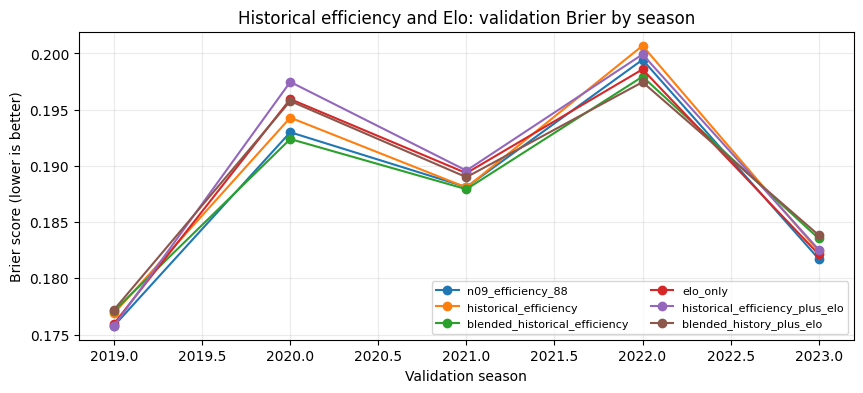

In [ ]:
pooled=pd.DataFrame([
    {'model':name,**evaluate(part.home_win,part.predicted_p_home_win)}
    for name,part in oof.groupby('model')
]).sort_values('brier').reset_index(drop=True)
print('Pooled model metrics:')
display(pooled.round(5))
by_year=fold_scores.pivot(index='validation_season',columns='model',values='brier')
deltas=by_year.sub(by_year['n09_efficiency_88'],axis=0)
print('Per-year Brier changes versus Notebook 09 baseline (negative is better):')
display(deltas.round(6))
base=oof.loc[oof.model.eq('n09_efficiency_88'),['game_id','home_win','predicted_p_home_win']].rename(
    columns={'predicted_p_home_win':'base_p'})
choice_name=pooled.iloc[0]['model']
choice=oof.loc[oof.model.eq(choice_name),['game_id','predicted_p_home_win']].rename(
    columns={'predicted_p_home_win':'choice_p'})
paired=base.merge(choice,on='game_id',validate='one_to_one')
paired['brier_improvement']=(paired.home_win-paired.base_p)**2-(paired.home_win-paired.choice_p)**2
print('Best model:',choice_name,'| Paired mean Brier improvement:',paired.brier_improvement.mean())
print('Games helped:',int(paired.brier_improvement.gt(0).sum()),
      '| harmed:',int(paired.brier_improvement.lt(0).sum()))
fig,ax=plt.subplots(figsize=(10,4))
for name in FEATURE_SETS:
    ax.plot(by_year.index,by_year[name],marker='o',label=name)
ax.set_xlabel('Validation season');ax.set_ylabel('Brier score (lower is better)')
ax.set_title('Historical efficiency and Elo: validation Brier by season')
ax.legend(loc='best',fontsize=8,ncol=2);ax.grid(alpha=.25)
plt.show()

## 8. Examine improvement by season stage



In [ ]:
stage_order=['0 FBS games','1–3 FBS games','4–7 FBS games','8+ FBS games']
stage_rows=[]
for (name,stage),part in oof.groupby(['model','season_stage'],observed=False):
    if part.empty: continue
    stage_rows.append({'model':name,'season_stage':stage,**evaluate(part.home_win,part.predicted_p_home_win)})
by_stage=pd.DataFrame(stage_rows)
pivot=by_stage.pivot(index='season_stage',columns='model',values='brier').reindex(stage_order)
print('Brier by season stage:')
display(pivot.round(5))
print('Brier differences versus baseline by season stage (negative is better):')
display(pivot.sub(pivot['n09_efficiency_88'],axis=0).round(5))
print('Sample counts by stage:')
display(by_stage.loc[by_stage.model.eq('n09_efficiency_88'),['season_stage','n_games']]
        .set_index('season_stage').reindex(stage_order))

Brier by season stage:


model,blended_historical_efficiency,blended_history_plus_elo,elo_only,historical_efficiency,historical_efficiency_plus_elo,n09_efficiency_88
season_stage,,,,,,
0 FBS games,0.18023,0.18128,0.17869,0.18000,0.18022,0.17817
1–3 FBS games,0.19009,0.18972,0.18918,0.19025,0.18988,0.18983
4–7 FBS games,0.18807,0.18995,0.18970,0.18847,0.19110,0.18779
8+ FBS games,0.18700,0.18721,0.18800,0.18861,0.18719,0.18760


Brier differences versus baseline by season stage (negative is better):


model,blended_historical_efficiency,blended_history_plus_elo,elo_only,historical_efficiency,historical_efficiency_plus_elo,n09_efficiency_88
season_stage,,,,,,
0 FBS games,0.00206,0.00311,0.00052,0.00183,0.00205,0.0
1–3 FBS games,0.00026,-0.00012,-0.00065,0.00041,0.00005,0.0
4–7 FBS games,0.00029,0.00216,0.00192,0.00068,0.00332,0.0
8+ FBS games,-0.00060,-0.00039,0.00041,0.00101,-0.00041,0.0


Sample counts by stage:


,n_games
season_stage,
0 FBS games,400
1–3 FBS games,997
4–7 FBS games,1229
8+ FBS games,1020


## 9. Export all reproducible features, predictions and diagnostics


In [ ]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
PROCESSED.mkdir(parents=True,exist_ok=True)
OUTPUTS={
    'matchups':PROCESSED/'matchup_features_historical_efficiency_elo.csv',
    'feature_manifest':PROCESSED/'historical_efficiency_elo_feature_manifest.json',
    'fold_scores':OUTPUT_DIR/'historical_efficiency_elo_fold_scores.csv',
    'pooled_scores':OUTPUT_DIR/'historical_efficiency_elo_pooled_scores.csv',
    'oof_predictions':OUTPUT_DIR/'historical_efficiency_elo_oof_predictions_2019_2023.csv',
    'stage_scores':OUTPUT_DIR/'historical_efficiency_elo_scores_by_stage.csv',
    'season_brier_deltas':OUTPUT_DIR/'historical_efficiency_elo_brier_deltas_by_season.csv',
}
expanded.to_csv(OUTPUTS['matchups'],index=False)
fold_scores.to_csv(OUTPUTS['fold_scores'],index=False)
pooled.to_csv(OUTPUTS['pooled_scores'],index=False)
oof.to_csv(OUTPUTS['oof_predictions'],index=False)
by_stage.to_csv(OUTPUTS['stage_scores'],index=False)
deltas.to_csv(OUTPUTS['season_brier_deltas'])
manifest={
    'experiment':'Notebook 10 historical efficiency and pregame Elo',
    'baseline':'Notebook 09 efficiency_without_scoring (88 features)',
    'feature_sets':FEATURE_SETS,
    'historical_efficiency_metrics':METRICS,
    'hist_rate_rule':'weighted sum of valid prior-season numerators / weighted sum of matching denominators',
    'hist_prior_seasons':[1,2,3],
    'hist_weights':[1.0,0.5,0.25],
    'blend_rule':'2^(-previous_same_season_FBS_games/4) on historical rate, remainder current; fallback to available rate',
    'elo_rules':{'initial_rating':ELO_CENTER,'k':ELO_K,'home_advantage_rating_points':ELO_HOME_BONUS,
                 'offseason_retention':ELO_OFFSEASON_KEEP,'probability_scale':400,
                 'update_games':'verified FBS vs FBS only','margin_of_victory_adjustment':False},
    'folds':folds,
    'primary_metric':'pooled validation Brier score',
    'test_seasons_reserved':sorted(TEST_SEASONS),
    'software':{'pandas':pd.__version__,'scikit_learn':sklearn.__version__},
    'baseline_reproduction_diagnostics':reproduction,
    'interpretation':'Exploratory repeated 2019–2023 validation, not untouched test; 2024–2025 not scored.',
    'future_feature_backlog':['Returning production','Recruiting/team talent','Coaching continuity','Further Elo tuning with train-only inner splits'],
}
OUTPUTS['feature_manifest'].write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Saved:')
for k,path in OUTPUTS.items(): print(f' {k}: {path}')
print('Test outcomes 2024–2025 not scored.')

Saved:
 matchups: /content/drive/MyDrive/CFB_Upset_Project/data/processed/matchup_features_historical_efficiency_elo.csv
 feature_manifest: /content/drive/MyDrive/CFB_Upset_Project/data/processed/historical_efficiency_elo_feature_manifest.json
 fold_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/historical_efficiency_elo_fold_scores.csv
 pooled_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/historical_efficiency_elo_pooled_scores.csv
 oof_predictions: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/historical_efficiency_elo_oof_predictions_2019_2023.csv
 stage_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/historical_efficiency_elo_scores_by_stage.csv
 season_brier_deltas: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/historical_efficiency_elo_brier_deltas_by_season.csv
Test outcomes 2024–2025 not scored.
